# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

In [2]:
from PIL import Image, ImageDraw
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", str(Path.cwd().parents[1] / "data")))
PALETTE = {"red": (220, 40, 40), "green": (40, 170, 70), "blue": (40, 80, 220), "yellow": (235, 200, 30),
           "purple": (140, 60, 180), "orange": (240, 130, 30), "gray": (150, 150, 150)}
SIZE = 224

def render(spec):
    """Рисует фигуры без перекрытий; координаты и размеры берутся из спецификации, случайности внутри нет."""
    img = Image.new("RGB", (SIZE, SIZE), tuple(spec["background"]))
    d = ImageDraw.Draw(img)
    for o in spec["objects"]:
        x, y, r = o["x"], o["y"], o["r"]
        col = PALETTE[o["color"]]
        if o["shape"] == "circle":
            d.ellipse([x - r, y - r, x + r, y + r], fill=col)
        elif o["shape"] == "square":
            d.rectangle([x - r, y - r, x + r, y + r], fill=col)
        else:
            d.polygon([(x, y - r), (x - r, y + r), (x + r, y + r)], fill=col)
    return img

_spec = {"background": [235, 235, 235], "objects": [{"shape": "circle", "color": "red", "x": 60, "y": 60, "r": 20},
                                                    {"shape": "triangle", "color": "blue", "x": 150, "y": 150, "r": 25}]}
assert np.array(render(_spec)).std() > 0 and np.array_equal(np.array(render(_spec)), np.array(render(_spec)))
print("палитра:", list(PALETTE))

палитра: ['red', 'green', 'blue', 'yellow', 'purple', 'orange', 'gray']


### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

In [3]:
SHAPES = ["circle", "square", "triangle"]
COUNTS = [1, 2, 3]
N_PER_COUNT = 4 if FAST_DEV_RUN else 50

def make_spec(scene_id, count, seed):
    rng = np.random.RandomState(seed)
    rare = rng.rand() < 0.2            # редкие случаи: мелкие фигуры или низкий контраст с фоном
    kind = rng.choice(["tiny", "low_contrast"]) if rare else "regular"
    background = [235, 235, 235] if kind != "low_contrast" else [165, 165, 165]
    objs, tries = [], 0
    while len(objs) < count:
        tries += 1
        assert tries < 10000
        r = int(rng.randint(8, 13)) if kind == "tiny" else int(rng.randint(18, 34))
        x, y = int(rng.randint(r + 4, SIZE - r - 4)), int(rng.randint(r + 4, SIZE - r - 4))
        if all((x - o["x"]) ** 2 + (y - o["y"]) ** 2 > (r + o["r"] + 8) ** 2 for o in objs):   # без перекрытий
            color = "gray" if kind == "low_contrast" else str(rng.choice([c for c in PALETTE if c != "gray"]))
            objs.append({"shape": str(rng.choice(SHAPES)), "color": color, "x": x, "y": y, "r": r})
    return {"scene_id": scene_id, "seed": int(seed), "count": count, "difficulty": kind, "background": background, "objects": objs}

specs = [make_spec(f"syn-{c}-{k:03d}", c, SEED * 1000 + 100 * c + k) for c in COUNTS for k in range(N_PER_COUNT)]
assert specs == [make_spec(s["scene_id"], s["count"], s["seed"]) for s in specs], "спецификации должны воспроизводиться по seed"
from collections import Counter
print(f"{len(specs)} сцен; по числу объектов {dict(Counter(s['count'] for s in specs))}; сложность {dict(Counter(s['difficulty'] for s in specs))}")

150 сцен; по числу объектов {1: 50, 2: 50, 3: 50}; сложность {'regular': 119, np.str_('low_contrast'): 11, np.str_('tiny'): 20}


### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

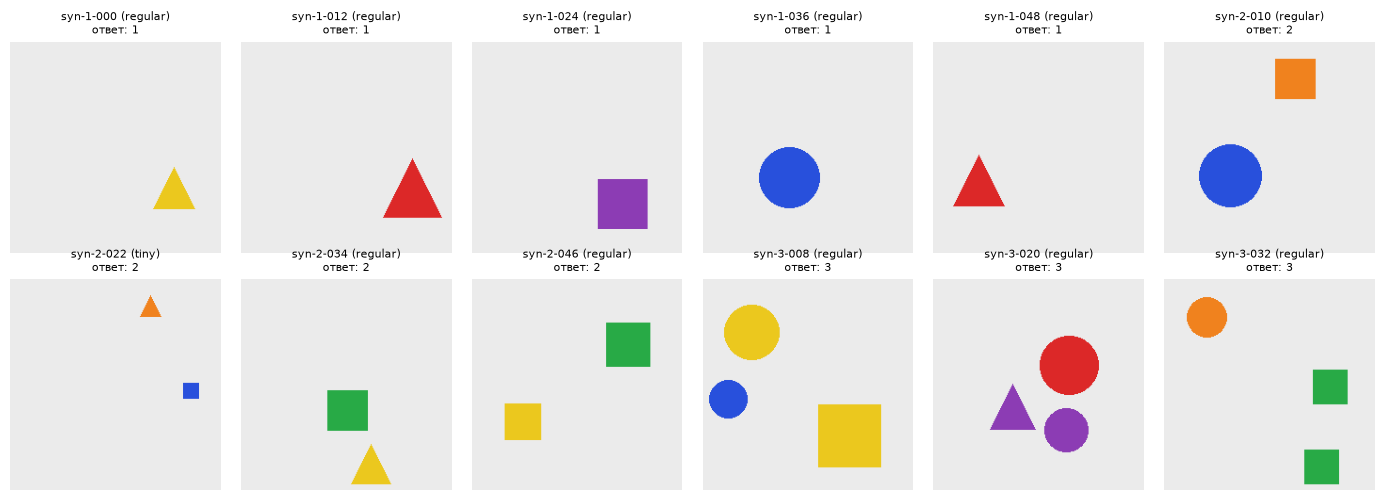

пример: {'scene_id': 'syn-1-000', 'path': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data/lab12/synthetic/syn-1-000.png', 'question': 'How many shapes are in the image? Answer with one integer.', 'answer': '1'}


In [4]:
SYN_DIR = DATA_ROOT / "lab12" / "synthetic"; SYN_DIR.mkdir(parents=True, exist_ok=True)
QUESTION = "How many shapes are in the image? Answer with one integer."
for s in specs:
    path = SYN_DIR / f"{s['scene_id']}.png"
    render(s).save(path)
    s.update(path=str(path), question=QUESTION, answer=str(s["count"]))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, s in zip(axes.flat, specs[::max(1, len(specs) // 12)][:12]):
    ax.imshow(Image.open(s["path"])); ax.axis("off"); ax.set_title(f"{s['scene_id']} ({s['difficulty']})\nответ: {s['answer']}", fontsize=8)
fig.tight_layout(); fig.savefig(ARTIFACTS / "synthetic_examples.png", dpi=80); plt.show()
print("пример:", {k: specs[0][k] for k in ("scene_id", "path", "question", "answer")})

### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [5]:
import hashlib, PIL
with open(ARTIFACTS / "synthetic_manifest.jsonl", "w") as f:
    for s in specs:
        f.write(json.dumps({**s, "provenance": {"generator": "procedural PIL renderer (render)", "seed": s["seed"], "pillow": PIL.__version__,
                                                  "synthetic": True}}, ensure_ascii=False) + "\n")
print("манифест:", ARTIFACTS / "synthetic_manifest.jsonl", "строк", len(specs))

манифест: artifacts/synthetic_manifest.jsonl строк 150


### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

In [6]:
import torch, re, transformers
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
assert DEVICE != "cpu", "Требуется GPU (CUDA или MPS) для реального VLM-инференса"
MODEL_ID = os.getenv("CV_VLM_MODEL", "Qwen/Qwen2.5-VL-3B-Instruct")
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, dtype=torch.float16, device_map={"": DEVICE}).eval()

@torch.no_grad()
def infer_image(path, prompt):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[Image.open(path).convert("RGB")], return_tensors="pt").to(DEVICE)
    generated = model.generate(**inputs, max_new_tokens=16, do_sample=False)
    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()

def parse_int(text):
    m = re.search(r"\d+", text)
    words = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
    if m: return int(m.group(0))
    w = next((v for k, v in words.items() if k in text.lower()), None)
    return w

ver_path = ARTIFACTS / "verification.jsonl"
done = {json.loads(l)["scene_id"] for l in ver_path.read_text().splitlines()} if ver_path.exists() else set()
pixel_hash = {}
t0 = time.time()
with open(ver_path, "a") as f:
    for s in specs:
        h = hashlib.sha256(np.array(Image.open(s["path"])).tobytes()).hexdigest()
        dup_of = pixel_hash.setdefault(h, s["scene_id"])
        if s["scene_id"] in done:
            continue
        raw = infer_image(s["path"], QUESTION)
        f.write(json.dumps({"scene_id": s["scene_id"], "expected": s["count"], "vlm_raw": raw, "vlm_count": parse_int(raw),
                            "pixel_sha256": h, "duplicate_of": dup_of if dup_of != s["scene_id"] else None, "model": MODEL_ID}) + "\n")
verification = [json.loads(l) for l in ver_path.read_text().splitlines()]
agree = np.mean([v["vlm_count"] == v["expected"] for v in verification])
print(f"VLM ответила на {len(verification)} сцен за {time.time() - t0:.0f} c; согласие с разметкой генератора {agree:.3f}; "
      f"дубликатов по пикселям: {sum(v['duplicate_of'] is not None for v in verification)}")
by_diff = {}
for v, s in zip(verification, specs):
    by_diff.setdefault(s["difficulty"], []).append(v["vlm_count"] == v["expected"])
print("согласие по сложности:", {k: round(float(np.mean(x)), 3) for k, x in by_diff.items()})

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


W1024 21:50:29.603000 53010 torch/_dynamo/convert_frame.py:2008] [1/8] torch._dynamo hit config.recompile_limit (8)
W1024 21:50:29.603000 53010 torch/_dynamo/convert_frame.py:2008] [1/8]    function: '_dequantize_4bit_compute' (/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/.venv/lib/python3.11/site-packages/bitsandbytes/backends/default/ops.py:262)
W1024 21:50:29.603000 53010 torch/_dynamo/convert_frame.py:2008] [1/8]    last reason: 1/6: shape[0] == 2048                                         # n = prod(shape)  # bitsandbytes/backends/default/ops.py:271 in _dequantize_4bit_compute
W1024 21:50:29.603000 53010 torch/_dynamo/convert_frame.py:2008] [1/8] User stack trace:
W1024 21:50:29.603000 53010 torch/_dynamo/convert_frame.py:2008] [1/8]   File "/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/.venv/lib/python3.11/site-packages/bitsandbytes/backends/default/ops.py", line 271, in _dequantize_4bit_compute
W1024 21:50:

VLM ответила на 150 сцен за 1107 c; согласие с разметкой генератора 0.993; дубликатов по пикселям: 0
согласие по сложности: {'regular': 0.992, np.str_('low_contrast'): 1.0, np.str_('tiny'): 1.0}


### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

In [7]:
spec_by_id = {s["scene_id"]: s for s in specs}
accepted = [spec_by_id[v["scene_id"]] for v in verification if v["vlm_count"] == v["expected"] and v["duplicate_of"] is None]
with open(ARTIFACTS / "accepted.jsonl", "w") as f:
    for s in accepted:
        f.write(json.dumps(s, ensure_ascii=False) + "\n")
print(f"принято {len(accepted)} из {len(specs)}; по числу объектов {dict(Counter(s['count'] for s in accepted))}")
rejected = [v for v in verification if v["vlm_count"] != v["expected"]]
print("примеры отклонённых:", [(v["scene_id"], v["expected"], v["vlm_raw"]) for v in rejected[:6]])

принято 149 из 150; по числу объектов {1: 50, 2: 50, 3: 49}
примеры отклонённых: [('syn-3-042', 3, '4')]


### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: проверенный real train/test manifest
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: замороженные признаки ResNet18 для трёх наборов
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: результаты классификаторов при четырёх долях синтетики
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: mixture_results.json и predictions.jsonl
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.